In [ ]:
import requests
import os
import json
import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud as wc
import matplotlib.pyplot as plt
# from config import API_KEY # create a config.py file with a variable named API_KEY

# key = API_KEY # get you key at https://newsapi.org/
API_KEY = os.getenv("MY_API_KEY")
if not API_KEY:
    raise ValueError("API_KEY not set. Please add it to .env")

# Run the next line on first start. Only required once:
# nltk.download('stopwords')

# Config Parameters
The code below allows inputs for sources and keywords. 

In [ ]:
# ------------------------
# CONFIGURATION PARAMETERS
# ------------------------


# Query parameters (edit these as needed)
keywords = [
    "US", "United States", "politics", "geopolitics", "foreign policy",
    "international relations", "diplomacy"
]

# Leave empty for all sources
sources = []  # e.g., ['politico', 'bbc-news', 'the-hill']

# Cache file
CACHE_FILE = f"news_cache.json"

# ------------------------------------
# BUILD QUERY STRING AND REQUEST URL
# ------------------------------------

query_string = " OR ".join(f'"{kw}"' for kw in keywords)
source_string = ",".join(sources) if sources else None

params = {
    "q": query_string,
    "language": "en",
    "sortBy": "publishedAt",
    "pageSize": 100, # Max allowed by NewsAPI per request
    "apiKey": API_KEY
}   
if source_string:
    params["sources"] = source_string

# --------------------------------
# FETCH DATA (With caching logic to allow saving API credits while testing.)
# --------------------------------

if os.path.exists(CACHE_FILE):
    with open(CACHE_FILE, "r", encoding="utf-8") as f:
        articles = json.load(f)
    print(f"Loaded {len(articles)} articles from cache: {CACHE_FILE}")
else:
    url = "https://newsapi.org/v2/everything"
    response = requests.get(url, params=params)
    data = response.json()
    
    if response.status_code != 200 or "articles" not in data:
        raise Exception(f"API error: {data.get('message', 'Unknown error')}")

    articles = data["articles"]
    
    with open(CACHE_FILE, "w", encoding="utf-8") as f:
        json.dump(articles, f, ensure_ascii=False, indent=2)
    print(f"Fetched and cached {len(articles)} articles to: {CACHE_FILE}")

# ----------------------------
# EXTRACT TEXT FOR PROCESSING
# ----------------------------

texts = []
for article in articles:
    title = article.get("title", "")
    description = article.get("description", "")
    summary = article.get("content", "")  # Not a true summary, but a partial body

    combined = f"{title} {description} {summary}"
    texts.append(combined)

# Preview first few entries
for i, text in enumerate(texts[:3]):
    print(f"\n--- Article {i+1} ---\n{text[:500]}...")


Loaded 94 articles from cache: news_cache.json

--- Article 1 ---
Type-Machine Article URL: https://arthi-chaud.github.io/posts/type-machine/
Comments URL: https://news.ycombinator.com/item?id=44958752
Points: 4
# Comments: 0 Code available on GitHub, package available on Hackage.
Introduction
In Haskell, we usually model data using algebraic data types, like this:
<table><tr><td>1
</td><td>dataMaybea=Nothing|Justa
<… [+14196 chars]...

--- Article 2 ---
Gen Z Isn’t The Problem. We Are. Some Leaders Are Brave Enough To Own It. Many workplaces are struggling with incoming workforce. But, haven't new generations always caused issues? And, who's fault is it? Experts share their opinions. The headline was hard to ignore. It spread across national media like wildfireequal parts funny, frustrating, and concerning. What was the headline?
26% of Gen Z Applicants Brought a Parent to a Job… [+10142 chars]...

--- Article 3 ---
Show HN: STIX – Institutional positioning in US equities revealed as 

# Generating the Word Cloud
The code below will take the news articles from your query above and generate a word cloud of the most used keywords.

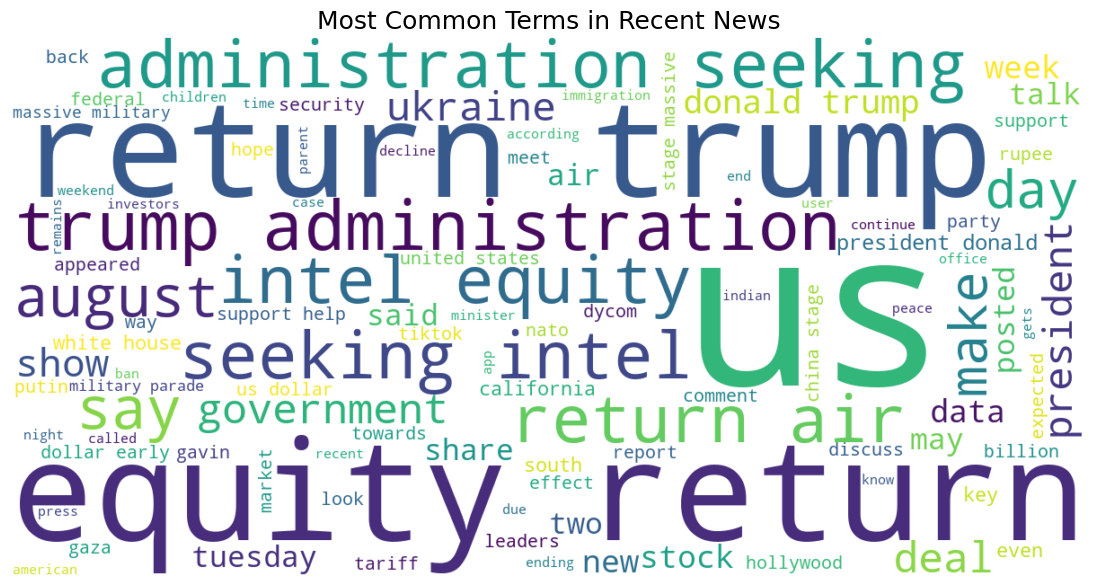

In [ ]:
# ----------------------
# Step 1: Combine all text
# ----------------------

# texts should already exist from the earlier script
# If not, reconstruct it from articles:
texts = []
for article in articles:
    title = article.get("title", "")
    description = article.get("description", "")
    content = article.get("content", "")  # partial article body

    combined = f"{title} {description} {content}"
    texts.append(combined)

all_text = " ".join(texts).lower()

# ----------------------
# Step 2: Remove stopwords
# ----------------------

stop_words = set(stopwords.words('english'))
filtered_words = [
    word for word in all_text.split()
    if word.isalpha() and word not in stop_words
]
clean_text = " ".join(filtered_words)

# ----------------------
# Step 3: Generate word cloud
# ----------------------
# font_path = r"C:/Windows/Fonts/arial.ttf"
wordcloud = wc(
    width=1200,
    height=600,
    background_color='white',
    max_words=100,
    # colormap='inferno'  # optional: 'viridis', 'plasma', 'cividis', etc.
).generate(clean_text)

# ----------------------
# Step 4: Display it
# ----------------------

plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Most Common Terms in Recent News', fontsize=18)
plt.show()